# Auto-Encoder Example

Build a 2 layers auto-encoder with JAX to compress images to a lower latent
space and then reconstruct them.

This example is using a low-level approach: the encoder and decoder are
plain Python functions, their weights are stored in a dictionary of arrays,
and the gradients are computed with `jax.grad`.

- Author: Aymeric Damien
- Project: [https://github.com/aymericdamien/JAX-Examples/](https://github.com/aymericdamien/JAX-Examples/)

## Auto-Encoder Overview

<img src="http://kvfrans.com/content/images/2016/08/autoenc.jpg" alt="ae" style="width: 800px;"/>

References:
- [Gradient-based learning applied to document recognition](http://yann.lecun.com/exdb/publis/pdf/lecun-01a.pdf). Y. LeCun, L. Bottou, Y. Bengio, and P. Haffner. Proceedings of the IEEE, 86(11):2278-2324, November 1998.

## MNIST Dataset Overview

This example is using MNIST handwritten digits. The dataset contains 60,000 examples for training and 10,000 examples for testing. The digits have been size-normalized and centered in a fixed-size image (28x28 pixels) with values from 0 to 255.

In this example, each image will be converted to float32, normalized to [0, 1] and flattened to a 1-D array of 784 features (28*28).

![MNIST Dataset](http://neuralnetworksanddeeplearning.com/images/mnist_100_digits.png)

More info: http://yann.lecun.com/exdb/mnist/

In [1]:
import os
import sys

import jax
import jax.numpy as jnp
import numpy as np
import optax

# Make the shared helpers of the 'common' folder importable.
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from common.datasets import load_mnist, batch_iterator

In [2]:
# MNIST Dataset parameters.
num_features = 784  # data features (img shape: 28*28).

# Training parameters.
learning_rate = 0.01
training_steps = 20000
batch_size = 256
display_step = 1000

# Network Parameters
num_hidden_1 = 128  # 1st layer num features.
num_hidden_2 = 64  # 2nd layer num features (the latent dim).

In [3]:
# Prepare MNIST data.
(x_train, y_train), (x_test, y_test) = load_mnist()
# Convert to float32.
x_train, x_test = x_train.astype(np.float32), x_test.astype(np.float32)
# Flatten images to 1-D vector of 784 features (28*28).
x_train, x_test = x_train.reshape([-1, num_features]), x_test.reshape([-1, num_features])
# Normalize images value from [0, 255] to [0, 1].
x_train, x_test = x_train / 255., x_test / 255.

In [4]:
# Shuffle and batch data (a simple data loader, see 'common/datasets.py').
train_data = batch_iterator(x_train, y_train, batch_size)

In [5]:
# Store layers weight & bias.

# Random values are generated from a random 'key', which is split to get a
# new key for every use.
keys = jax.random.split(jax.random.key(0), 8)

# A random value generator to initialize weights.
def random_normal(key, shape):
    return 0.05 * jax.random.normal(key, shape)

# All the model parameters, gathered in a dictionary.
params = {
    'weights': {
        'encoder_h1': random_normal(keys[0], [num_features, num_hidden_1]),
        'encoder_h2': random_normal(keys[1], [num_hidden_1, num_hidden_2]),
        'decoder_h1': random_normal(keys[2], [num_hidden_2, num_hidden_1]),
        'decoder_h2': random_normal(keys[3], [num_hidden_1, num_features]),
    },
    'biases': {
        'encoder_b1': random_normal(keys[4], [num_hidden_1]),
        'encoder_b2': random_normal(keys[5], [num_hidden_2]),
        'decoder_b1': random_normal(keys[6], [num_hidden_1]),
        'decoder_b2': random_normal(keys[7], [num_features]),
    },
}

In [6]:
# Building the encoder.
def encoder(params, x):
    weights, biases = params['weights'], params['biases']
    # Encoder Hidden layer with sigmoid activation.
    layer_1 = jax.nn.sigmoid(jnp.add(jnp.matmul(x, weights['encoder_h1']),
                                     biases['encoder_b1']))
    # Encoder Hidden layer with sigmoid activation.
    layer_2 = jax.nn.sigmoid(jnp.add(jnp.matmul(layer_1, weights['encoder_h2']),
                                     biases['encoder_b2']))
    return layer_2


# Building the decoder.
def decoder(params, x):
    weights, biases = params['weights'], params['biases']
    # Decoder Hidden layer with sigmoid activation.
    layer_1 = jax.nn.sigmoid(jnp.add(jnp.matmul(x, weights['decoder_h1']),
                                     biases['decoder_b1']))
    # Decoder Hidden layer with sigmoid activation.
    layer_2 = jax.nn.sigmoid(jnp.add(jnp.matmul(layer_1, weights['decoder_h2']),
                                     biases['decoder_b2']))
    return layer_2

In [7]:
# Mean square loss between original images and reconstructed ones.
def mean_square(reconstructed, original):
    return jnp.mean(jnp.power(original - reconstructed, 2))

# Adam optimizer.
optimizer = optax.adam(learning_rate)
# The optimizer state (Adam's moving averages) is stored outside of the optimizer.
opt_state = optimizer.init(params)

In [8]:
# Optimization process.
# @jax.jit compiles the function with XLA, so it runs much faster
# (see '1_Introduction/transformations.py').
@jax.jit
def run_optimization(params, opt_state, x):
    # Define the loss as a function of the parameters, to differentiate it.
    def loss_fn(params):
        reconstructed_image = decoder(params, encoder(params, x))
        return mean_square(reconstructed_image, x)

    # Compute the loss and its gradients with respect to every parameter.
    loss, gradients = jax.value_and_grad(loss_fn)(params)

    # Update W and b following gradients.
    updates, opt_state = optimizer.update(gradients, opt_state)
    params = optax.apply_updates(params, updates)

    # JAX arrays can't be modified in place: return the updated values.
    return params, opt_state, loss

In [9]:
# Run training for the given number of steps.
for step in range(training_steps + 1):
    # Get the next batch of data (only the images are needed, not the labels).
    batch_x, _ = next(train_data)
    # Run the optimization.
    params, opt_state, loss = run_optimization(params, opt_state, batch_x)

    if step % display_step == 0:
        print("step: %i, loss: %f" % (step, loss))

step: 0, loss: 0.232220


step: 1000, loss: 0.016763


step: 2000, loss: 0.010899


step: 3000, loss: 0.008152


step: 4000, loss: 0.007130


step: 5000, loss: 0.006162


... (11 outputs left out)

step: 17000, loss: 0.003937


step: 18000, loss: 0.003592


step: 19000, loss: 0.003849


step: 20000, loss: 0.003608


In [10]:
# Testing and Visualization.
import matplotlib.pyplot as plt

Original Images


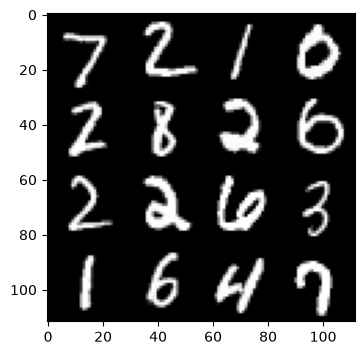

Reconstructed Images


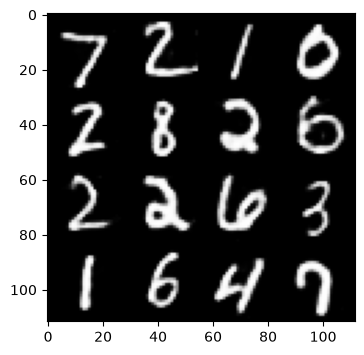

In [11]:
# Encode and decode images from test set and visualize their reconstruction.
n = 4
canvas_orig = np.empty((28 * n, 28 * n))
canvas_recon = np.empty((28 * n, 28 * n))
for i in range(n):
    # Take the i-th batch of the test set.
    batch_x = x_test[i * batch_size:(i + 1) * batch_size]
    # Encode and decode the digit image.
    reconstructed_images = decoder(params, encoder(params, batch_x))
    # Display original images.
    for j in range(n):
        # Draw the original digits.
        img = batch_x[j].reshape([28, 28])
        canvas_orig[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = img
    # Display reconstructed images.
    for j in range(n):
        # Draw the reconstructed digits.
        reconstr_img = np.asarray(reconstructed_images[j]).reshape([28, 28])
        canvas_recon[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = reconstr_img

print("Original Images")
plt.figure(figsize=(n, n))
plt.imshow(canvas_orig, origin="upper", cmap="gray")
plt.show()

print("Reconstructed Images")
plt.figure(figsize=(n, n))
plt.imshow(canvas_recon, origin="upper", cmap="gray")
plt.show()